In [2]:
# ============================================================
# Cell 1
# BitFit 完整实验环境
# 新 Colab 可直接运行
# ============================================================

import os
import sys
import subprocess
import shutil
import importlib
from pathlib import Path

print("=" * 70)
print("BitFit 实验环境准备")
print("=" * 70)

print("Python:", sys.version)

# ------------------------------------------------------------
# 1. 挂载 Google Drive
# ------------------------------------------------------------

from google.colab import drive

# ------------------------------------------------------------
# 2. 创建保存目录
# ------------------------------------------------------------

DRIVE_ROOT = "/content/drive/MyDrive/nlp实践"
MODEL_ROOT = os.path.join(DRIVE_ROOT, "BitFit_models")
RESULT_ROOT = os.path.join(DRIVE_ROOT, "BitFit_results")

os.makedirs(DRIVE_ROOT, exist_ok=True)
os.makedirs(MODEL_ROOT, exist_ok=True)
os.makedirs(RESULT_ROOT, exist_ok=True)

print("实验保存目录：")
print(DRIVE_ROOT)
print(MODEL_ROOT)
print(RESULT_ROOT)

# ------------------------------------------------------------
# 3. 获取 BitFit GitHub
# ------------------------------------------------------------

BITFIT_DIR = "/content/BitFit"

if not os.path.exists(os.path.join(BITFIT_DIR, "glue_evaluator.py")):

    if os.path.exists(BITFIT_DIR):
        shutil.rmtree(BITFIT_DIR)

    print("\n正在 clone BitFit GitHub...")

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/benzakenelad/BitFit.git",
            BITFIT_DIR
        ],
        check=True
    )

else:
    print("\nBitFit 已存在：", BITFIT_DIR)

print("BitFit 路径：", BITFIT_DIR)
print(
    "glue_evaluator.py：",
    os.path.exists(os.path.join(BITFIT_DIR, "glue_evaluator.py"))
)
print(
    "utils.py：",
    os.path.exists(os.path.join(BITFIT_DIR, "utils.py"))
)

# ------------------------------------------------------------
# 4. 设置 Python 路径
# ------------------------------------------------------------

if BITFIT_DIR not in sys.path:
    sys.path.insert(0, BITFIT_DIR)

os.chdir(BITFIT_DIR)

print("当前目录：", os.getcwd())
print("sys.path[0]：", sys.path[0])

# ------------------------------------------------------------
# 5. GPU 检查
# ------------------------------------------------------------

import torch

print("\n" + "=" * 70)
print("GPU")
print("=" * 70)

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "CUDA:",
        torch.version.cuda
    )
else:
    raise RuntimeError("没有检测到 CUDA GPU，停止实验。")

print("\n环境准备完成。")

BitFit 实验环境准备
Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
实验保存目录：
/content/drive/MyDrive/nlp实践
/content/drive/MyDrive/nlp实践/BitFit_models
/content/drive/MyDrive/nlp实践/BitFit_results

BitFit 已存在： /content/BitFit
BitFit 路径： /content/BitFit
glue_evaluator.py： True
utils.py： True
当前目录： /content/BitFit
sys.path[0]： /content/BitFit

GPU
Torch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA: 12.8

环境准备完成。


In [3]:
# ============================================================
# Cell 2
# BitFit 兼容处理
# ============================================================

import os
import sys
import types
import importlib
import torch

BITFIT_DIR = "/content/BitFit"

os.chdir(BITFIT_DIR)

if BITFIT_DIR not in sys.path:
    sys.path.insert(0, BITFIT_DIR)

print("=" * 70)
print("BitFit 兼容处理")
print("=" * 70)

# ------------------------------------------------------------
# 1. 导入 transformers
# ------------------------------------------------------------

import transformers

print("Transformers:", transformers.__version__)

# ------------------------------------------------------------
# 2. 兼容旧代码中的 transformers.optimization.AdamW
# ------------------------------------------------------------

try:
    from transformers.optimization import AdamW
    print("transformers.optimization.AdamW 已存在")
except ImportError:

    from torch.optim import AdamW

    import transformers.optimization as optimization

    optimization.AdamW = AdamW

    print("已注入兼容版 AdamW")

# ------------------------------------------------------------
# 3. 确保 BitFit 根目录可导入
# ------------------------------------------------------------

import utils

print("utils 导入成功：", utils.__file__)

# ------------------------------------------------------------
# 4. 加载 glue_evaluator
# ------------------------------------------------------------

if "glue_evaluator" in sys.modules:
    del sys.modules["glue_evaluator"]

spec = importlib.util.spec_from_file_location(
    "glue_evaluator",
    os.path.join(BITFIT_DIR, "glue_evaluator.py")
)

glue_evaluator = importlib.util.module_from_spec(spec)

sys.modules["glue_evaluator"] = glue_evaluator

spec.loader.exec_module(glue_evaluator)

GLUEvaluator = glue_evaluator.GLUEvaluator

print("GLUEvaluator 导入成功")

print("=" * 70)
print("兼容处理完成")
print("=" * 70)

BitFit 兼容处理
Transformers: 5.16.1
已注入兼容版 AdamW
utils 导入成功： /content/BitFit/utils.py
GLUEvaluator 导入成功
兼容处理完成


In [4]:
# ============================================================
# Cell 3
# RTE 数据集预检
# ============================================================

import os
import sys
import torch

os.chdir("/content/BitFit")

print("=" * 70)
print("RTE 数据集预检")
print("=" * 70)

try:

    test_ev = GLUEvaluator(
        "rte",
        "bert-base-cased",
        "cuda"
    )

    test_ev.preprocess_dataset(
        padding="max_length",
        max_sequence_len=128,
        batch_size=8
    )

    print("\nRTE 加载成功")

    print(
        "Train:",
        len(test_ev.data_loaders["train"].dataset)
    )

    print(
        "Validation:",
        len(test_ev.data_loaders["validation"].dataset)
    )

    if "test" in test_ev.data_loaders:
        print(
            "Test:",
            len(test_ev.data_loaders["test"].dataset)
        )

except Exception as e:

    print("\n" + "=" * 70)
    print("RTE 加载失败")
    print("=" * 70)

    print(repr(e))

    raise RuntimeError(
        "\nRTE 数据集没有成功加载。\n"
        "不要继续运行 12 个实验。\n"
        "请先解决数据集问题。"
    )

print("\nRTE 预检通过，可以开始正式实验。")

RTE 数据集预检


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]


RTE 加载成功
Train: 2490
Validation: 277
Test: 3000

RTE 预检通过，可以开始正式实验。


In [5]:
# ============================================================
# Cell 4
# 完整实验函数
# ============================================================

import os
import sys
import json
import time
import random
import copy
import traceback

import numpy as np
import torch

from pathlib import Path

# ------------------------------------------------------------
# 路径
# ------------------------------------------------------------

BITFIT_DIR = "/content/BitFit"

DRIVE_ROOT = "/content/drive/MyDrive/nlp实践"

MODEL_ROOT = os.path.join(
    DRIVE_ROOT,
    "BitFit_models"
)

RESULT_ROOT = os.path.join(
    DRIVE_ROOT,
    "BitFit_results"
)

RESULTS_PATH = os.path.join(
    RESULT_ROOT,
    "bitfit_stage_b.json"
)

os.makedirs(MODEL_ROOT, exist_ok=True)
os.makedirs(RESULT_ROOT, exist_ok=True)

os.chdir(BITFIT_DIR)

# ------------------------------------------------------------
# 全局结果
# ------------------------------------------------------------

all_results = []

# ------------------------------------------------------------
# 读取已经存在的结果
# ------------------------------------------------------------

if os.path.exists(RESULTS_PATH):

    try:

        with open(
            RESULTS_PATH,
            "r",
            encoding="utf-8"
        ) as f:

            all_results = json.load(f)

        print(
            "发现已有结果：",
            len(all_results),
            "个实验"
        )

    except Exception as e:

        print(
            "已有 JSON 读取失败，将重新开始结果列表：",
            repr(e)
        )

        all_results = []

else:

    print("没有发现旧结果，从零开始。")


# ------------------------------------------------------------
# 保存 JSON
# ------------------------------------------------------------

def save_results():

    tmp_path = RESULTS_PATH + ".tmp"

    with open(
        tmp_path,
        "w",
        encoding="utf-8"
    ) as f:

        json.dump(
            all_results,
            f,
            indent=2,
            ensure_ascii=False
        )

    os.replace(
        tmp_path,
        RESULTS_PATH
    )


# ------------------------------------------------------------
# 实验 key
# ------------------------------------------------------------

def experiment_key(
    method,
    lr,
    seed
):

    return (
        str(method),
        float(lr),
        int(seed)
    )


# ------------------------------------------------------------
# 判断是否已经完成
# ------------------------------------------------------------

def has_completed(
    method,
    lr,
    seed
):

    key = experiment_key(
        method,
        lr,
        seed
    )

    for r in all_results:

        try:

            old_key = experiment_key(
                r["method"],
                r["lr"],
                r["seed"]
            )

            if old_key == key:
                return True

        except Exception:
            pass

    return False


# ------------------------------------------------------------
# 参数快照
# ------------------------------------------------------------

def snapshot_trainable_parameters(model):

    result = {}

    for name, param in model.named_parameters():

        if param.requires_grad:

            result[name] = (
                param.detach()
                .cpu()
                .clone()
            )

    return result


# ------------------------------------------------------------
# 检查参数是否发生变化
# ------------------------------------------------------------

def check_parameter_updates(
    model,
    before
):

    updated = []
    not_updated = []

    max_change = 0.0

    for name, param in model.named_parameters():

        if not param.requires_grad:
            continue

        after = (
            param.detach()
            .cpu()
        )

        if name not in before:

            continue

        old = before[name]

        diff = (
            after - old
        ).abs()

        change = diff.max().item()

        max_change = max(
            max_change,
            change
        )

        if torch.any(diff != 0):

            updated.append(name)

        else:

            not_updated.append(name)

    return (
        updated,
        not_updated,
        max_change
    )


# ------------------------------------------------------------
# 检查梯度
# ------------------------------------------------------------

def check_gradients(model):

    with_grad = []
    without_grad = []

    max_grad = 0.0

    for name, param in model.named_parameters():

        if not param.requires_grad:
            continue

        if param.grad is None:

            without_grad.append(name)

        else:

            with_grad.append(name)

            value = (
                param.grad.detach()
                .abs()
                .max()
                .item()
            )

            max_grad = max(
                max_grad,
                value
            )

    return (
        with_grad,
        without_grad,
        max_grad
    )


# ------------------------------------------------------------
# optimizer steps
# ------------------------------------------------------------

def get_optimizer_steps(optimizer):

    steps = []

    for state in optimizer.state.values():

        if "step" not in state:
            continue

        step = state["step"]

        if torch.is_tensor(step):
            step = step.item()

        steps.append(float(step))

    return sorted(
        set(steps)
    )


# ------------------------------------------------------------
# 保存模型
# ------------------------------------------------------------

def save_model_to_drive(
    ev,
    method,
    lr,
    seed
):

    folder_name = (
        method
        .replace(" ", "_")
        .replace("/", "_")
    )

    folder_name += (
        f"_lr{lr:g}_seed{seed}"
    )

    model_dir = os.path.join(
        MODEL_ROOT,
        folder_name
    )

    os.makedirs(
        model_dir,
        exist_ok=True
    )

    ev.model.save_pretrained(
        model_dir
    )

    try:

        if hasattr(
            ev,
            "tokenizer"
        ) and ev.tokenizer is not None:

            ev.tokenizer.save_pretrained(
                model_dir
            )

    except Exception:
        pass

    return model_dir


# ------------------------------------------------------------
# 单个实验
# ------------------------------------------------------------

def run_one(
    method,
    trainable_components,
    encoder_trainable,
    lr,
    seed
):

    global all_results

    print("\n")
    print("=" * 70)
    print("开始实验")
    print("METHOD:", method)
    print("LR:", lr)
    print("SEED:", seed)
    print("=" * 70)

    # --------------------------------------------------------
    # seed
    # --------------------------------------------------------

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()

    # --------------------------------------------------------
    # evaluator
    # --------------------------------------------------------

    ev = GLUEvaluator(
        "rte",
        "bert-base-cased",
        "cuda"
    )

    # --------------------------------------------------------
    # dataset
    # --------------------------------------------------------

    ev.preprocess_dataset(
        padding="max_length",
        max_sequence_len=128,
        batch_size=8
    )

    # --------------------------------------------------------
    # training preparation
    # --------------------------------------------------------

    ev.training_preparation(
        learning_rate=lr,
        optimizer="adamw",
        encoder_trainable=encoder_trainable,
        trainable_components=trainable_components,
        verbose=False
    )

    ev.model = ev.model.to(
        ev.device
    )

    # --------------------------------------------------------
    # trainable parameters
    # --------------------------------------------------------

    trainable_items = [
        (name, p)
        for name, p in ev.model.named_parameters()
        if p.requires_grad
    ]

    trainable_params = sum(
        p.numel()
        for _, p in trainable_items
    )

    trainable_tensors = len(
        trainable_items
    )

    print("\nTrainable parameters:")
    print(
        trainable_params
    )

    print(
        "Trainable tensors:",
        trainable_tensors
    )

    for name, p in trainable_items:

        print(
            " ",
            name,
            tuple(p.shape)
        )

    # --------------------------------------------------------
    # 参数快照
    # --------------------------------------------------------

    before_params = (
        snapshot_trainable_parameters(
            ev.model
        )
    )

    # --------------------------------------------------------
    # GPU memory reset
    # --------------------------------------------------------

    if torch.cuda.is_available():

        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    # --------------------------------------------------------
    # training
    # --------------------------------------------------------

    start_time = time.time()

    ev.train_and_evaluate(
        num_epochs=4,
        evaluation_frequency=1
    )

    elapsed = (
        time.time()
        - start_time
    )

    # --------------------------------------------------------
    # evaluation
    # --------------------------------------------------------

    val_accs = list(
        ev.evaluations[
            "validation"
        ][
            "Accuracy"
        ]
    )

    train_accs = list(
        ev.evaluations.get(
            "train",
            {}
        ).get(
            "Accuracy",
            []
        )
    )

    # --------------------------------------------------------
    # gradient check
    # --------------------------------------------------------

    (
        grad_with,
        grad_without,
        max_grad
    ) = check_gradients(
        ev.model
    )

    # --------------------------------------------------------
    # update check
    # --------------------------------------------------------

    (
        updated,
        not_updated,
        max_change
    ) = check_parameter_updates(
        ev.model,
        before_params
    )

    # --------------------------------------------------------
    # optimizer steps
    # --------------------------------------------------------

    optimizer_steps = (
        get_optimizer_steps(
            ev.optimizer
        )
    )

    # --------------------------------------------------------
    # GPU memory
    # --------------------------------------------------------

    if torch.cuda.is_available():

        peak_memory = (
            torch.cuda
            .max_memory_allocated()
            / 1024**3
        )

    else:

        peak_memory = 0.0

    # --------------------------------------------------------
    # model save
    # --------------------------------------------------------

    model_dir = save_model_to_drive(
        ev,
        method,
        lr,
        seed
    )

    # --------------------------------------------------------
    # result
    # --------------------------------------------------------

    rec = {

        "method": method,

        "lr": float(lr),

        "seed": int(seed),

        "task": "rte",

        "model": "bert-base-cased",

        "epochs": 4,

        "batch_size": 8,

        "max_sequence_len": 128,

        "trainable_params":
            int(trainable_params),

        "trainable_tensors":
            int(trainable_tensors),

        "trainable_names":
            [
                name
                for name, _
                in trainable_items
            ],

        "val_accs":
            [
                float(x)
                for x in val_accs
            ],

        "train_accs":
            [
                float(x)
                for x in train_accs
            ],

        "final_val_acc":
            float(val_accs[-1]),

        "best_val_acc":
            float(max(val_accs)),

        "elapsed":
            float(elapsed),

        "peak_mem":
            float(peak_memory),

        "optimizer_steps":
            optimizer_steps,

        "gradient_tensors":
            len(grad_with),

        "gradient_missing_tensors":
            len(grad_without),

        "max_gradient":
            float(max_grad),

        "updated_tensors":
            len(updated),

        "not_updated_tensors":
            len(not_updated),

        "updated_names":
            updated,

        "not_updated_names":
            not_updated,

        "max_parameter_change":
            float(max_change),

        "model_dir":
            model_dir
    }

    # --------------------------------------------------------
    # 打印验证信息
    # --------------------------------------------------------

    print("\n")
    print("=" * 70)
    print("实验完成")
    print("=" * 70)

    print(
        "METHOD:",
        method
    )

    print(
        "LR:",
        lr
    )

    print(
        "SEED:",
        seed
    )

    print(
        "Trainable parameters:",
        trainable_params
    )

    print(
        "Trainable tensors:",
        trainable_tensors
    )

    print(
        "Gradient tensors:",
        len(grad_with)
    )

    print(
        "Updated tensors:",
        len(updated)
    )

    print(
        "Not updated tensors:",
        len(not_updated)
    )

    print(
        "Optimizer steps:",
        optimizer_steps
    )

    print(
        "Best validation:",
        max(val_accs)
    )

    print(
        "Final validation:",
        val_accs[-1]
    )

    print(
        "Elapsed:",
        f"{elapsed:.2f}s"
    )

    print(
        "Peak GPU memory:",
        f"{peak_memory:.3f} GB"
    )

    print(
        "Model saved:",
        model_dir
    )

    # --------------------------------------------------------
    # 追加结果并立即保存
    # --------------------------------------------------------

    all_results.append(
        rec
    )

    save_results()

    print(
        "JSON 已立即保存：",
        RESULTS_PATH
    )

    # --------------------------------------------------------
    # 清理
    # --------------------------------------------------------

    del ev

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return rec

没有发现旧结果，从零开始。


In [6]:
# ============================================================
# Cell 5
# 自动续跑
# ============================================================

def run_grid(
    method,
    components,
    encoder_trainable,
    lr,
    seeds
):

    print("\n")
    print("=" * 70)
    print("实验组：", method)
    print("LR：", lr)
    print("Seeds：", seeds)
    print("=" * 70)

    for seed in seeds:

        if has_completed(
            method,
            lr,
            seed
        ):

            print(
                f"\n跳过已完成："
                f"{method} | LR={lr} | seed={seed}"
            )

            continue

        try:

            run_one(
                method=method,
                trainable_components=components,
                encoder_trainable=encoder_trainable,
                lr=lr,
                seed=seed
            )

        except Exception as e:

            print("\n")
            print("=" * 70)
            print("本次实验失败")
            print("=" * 70)

            print(
                "METHOD:",
                method
            )

            print(
                "LR:",
                lr
            )

            print(
                "SEED:",
                seed
            )

            print(
                "ERROR:",
                repr(e)
            )

            traceback.print_exc()

            # 清理 GPU
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

            # ------------------------------------------------
            # 注意：
            # 失败实验不写入 all_results
            # 因此下次重新运行时会自动重试
            # ------------------------------------------------

            continue

    print("\n")
    print("=" * 70)
    print("实验组结束：", method)
    print("=" * 70)



实验组： BitFit
LR： 0.0005
Seeds： [42, 123, 2026]


开始实验
METHOD: BitFit
LR: 0.0005
SEED: 42


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
104450
Trainable tensors: 100
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.0.output.dense.bias (768,)
  bert.encoder.layer.0.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.attention.self.key.bias (768,)
  bert.encoder.layer.1.attention.self.value.bias (768,)
  bert.encoder.layer.1.attention.output.dense.bias (768,)
  bert.encoder.layer.1.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.output.dense.bias (768,)
  bert.encoder.layer.1.output.LayerNorm.bias (768,)
  bert.encoder.layer.2.at

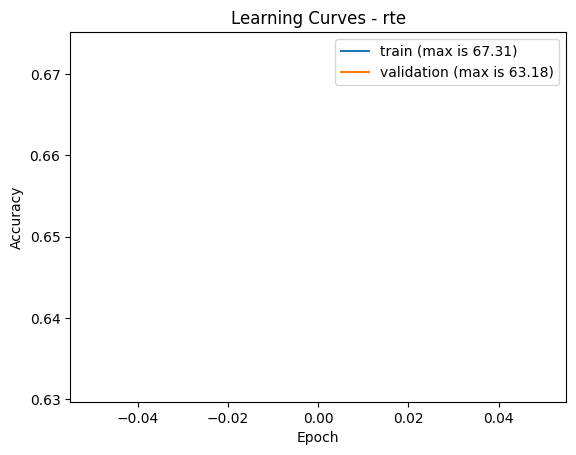

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.642
TRAIN ACC: 0.69438
VALIDATION ACC: 0.64621



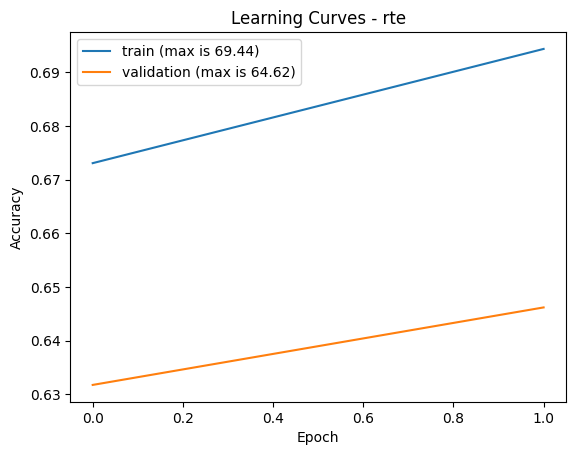

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.594
TRAIN ACC: 0.71245
VALIDATION ACC: 0.66787



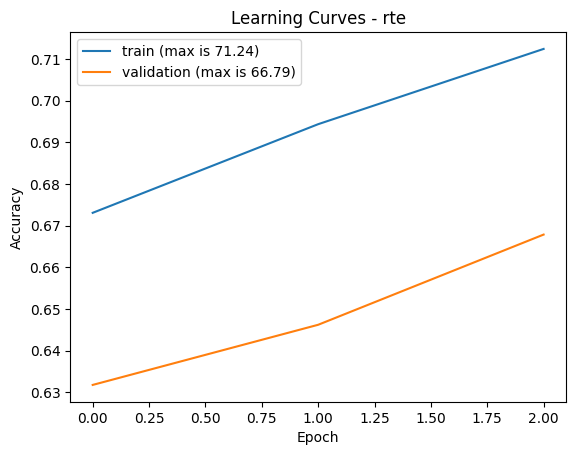

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.568
TRAIN ACC: 0.78313
VALIDATION ACC: 0.70397



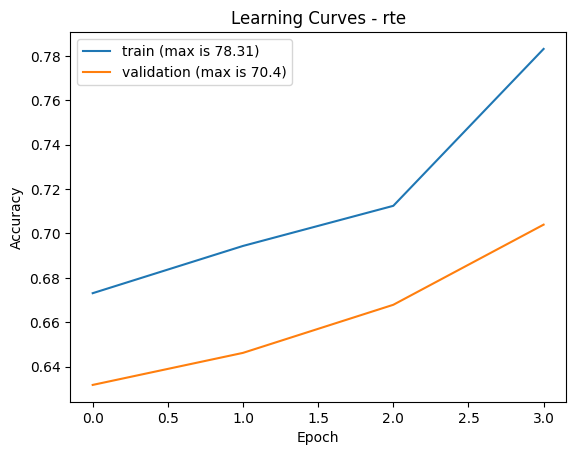

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: BitFit
LR: 0.0005
SEED: 42
Trainable parameters: 104450
Trainable tensors: 100
Gradient tensors: 0
Updated tensors: 100
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.703971119133574
Final validation: 0.703971119133574
Elapsed: 220.90s
Peak GPU memory: 0.828 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/BitFit_lr0.0005_seed42
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: BitFit
LR: 0.0005
SEED: 123


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
104450
Trainable tensors: 100
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.0.output.dense.bias (768,)
  bert.encoder.layer.0.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.attention.self.key.bias (768,)
  bert.encoder.layer.1.attention.self.value.bias (768,)
  bert.encoder.layer.1.attention.output.dense.bias (768,)
  bert.encoder.layer.1.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.output.dense.bias (768,)
  bert.encoder.layer.1.output.LayerNorm.bias (768,)
  bert.encoder.layer.2.at

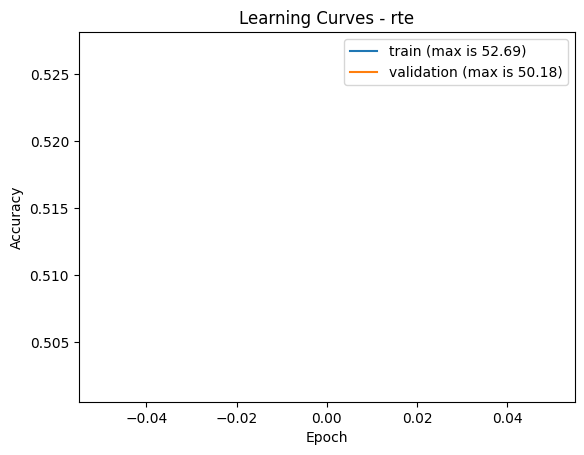

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.651
TRAIN ACC: 0.70602
VALIDATION ACC: 0.6426



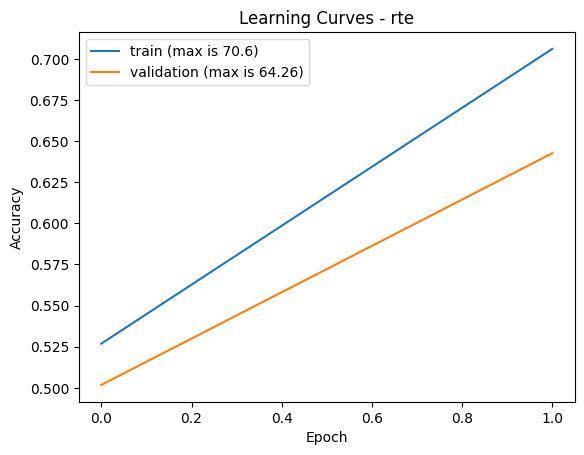

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.601
TRAIN ACC: 0.69398
VALIDATION ACC: 0.63177



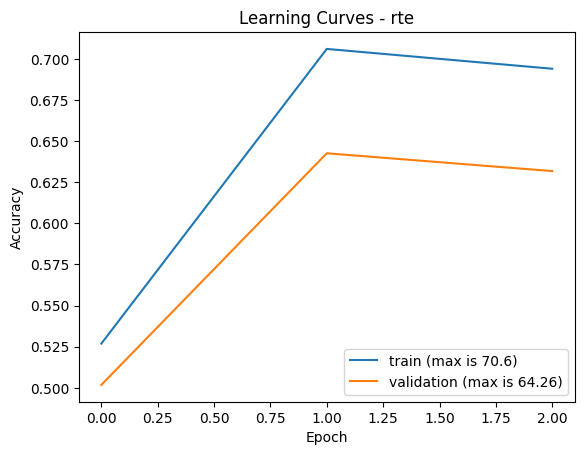

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.588
TRAIN ACC: 0.75663
VALIDATION ACC: 0.64621



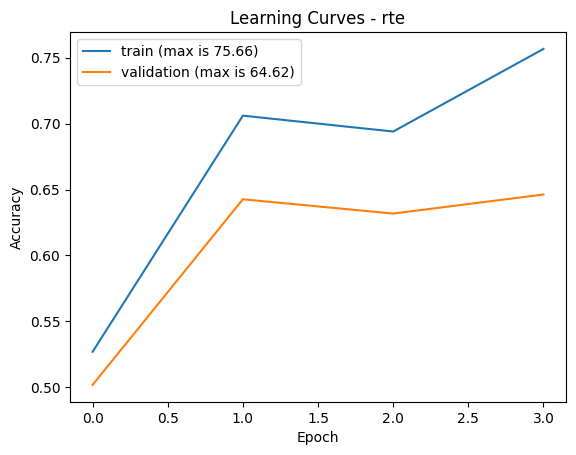

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: BitFit
LR: 0.0005
SEED: 123
Trainable parameters: 104450
Trainable tensors: 100
Gradient tensors: 0
Updated tensors: 100
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6462093862815884
Final validation: 0.6462093862815884
Elapsed: 230.89s
Peak GPU memory: 0.828 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/BitFit_lr0.0005_seed123
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: BitFit
LR: 0.0005
SEED: 2026


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
104450
Trainable tensors: 100
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.0.output.dense.bias (768,)
  bert.encoder.layer.0.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.attention.self.key.bias (768,)
  bert.encoder.layer.1.attention.self.value.bias (768,)
  bert.encoder.layer.1.attention.output.dense.bias (768,)
  bert.encoder.layer.1.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.output.dense.bias (768,)
  bert.encoder.layer.1.output.LayerNorm.bias (768,)
  bert.encoder.layer.2.at

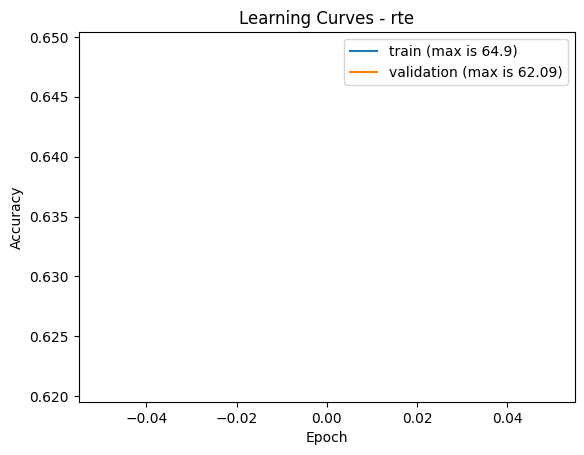

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.638
TRAIN ACC: 0.71687
VALIDATION ACC: 0.67148



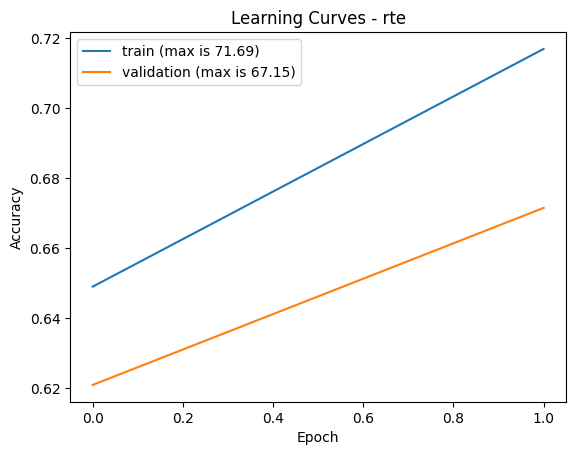

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.611
TRAIN ACC: 0.67149
VALIDATION ACC: 0.57762



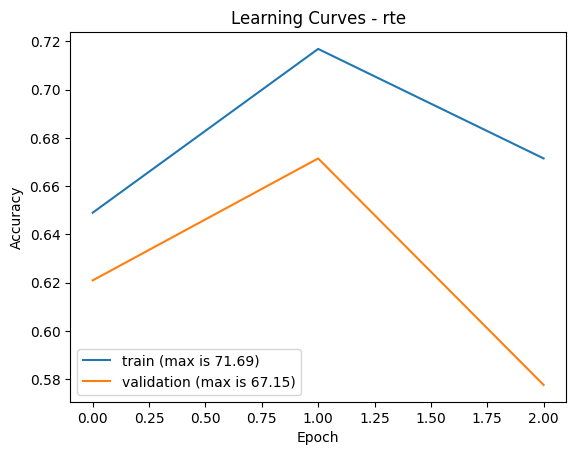

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.582
TRAIN ACC: 0.74257
VALIDATION ACC: 0.63899



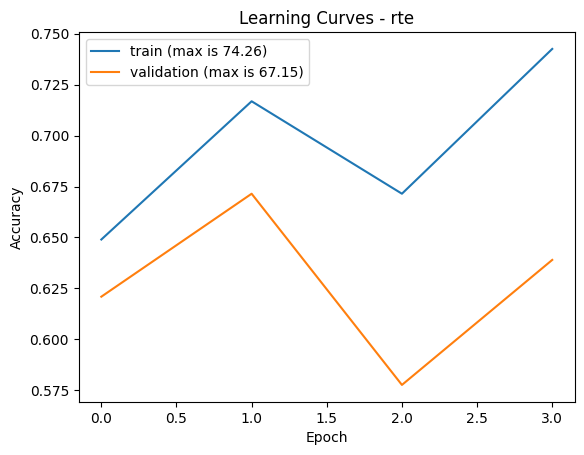

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: BitFit
LR: 0.0005
SEED: 2026
Trainable parameters: 104450
Trainable tensors: 100
Gradient tensors: 0
Updated tensors: 100
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6714801444043321
Final validation: 0.6389891696750902
Elapsed: 231.47s
Peak GPU memory: 0.828 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/BitFit_lr0.0005_seed2026
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


实验组结束： BitFit


实验组： Classifier-only
LR： 0.001
Seeds： [42, 123, 2026]


开始实验
METHOD: Classifier-only
LR: 0.001
SEED: 42


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
1538
Trainable tensors: 2
  classifier.weight (2, 768)
  classifier.bias (2,)
EPOCH: 0   TRAIN: 2490/2490   LOSS: 0.746
TRAIN ACC: 0.49759
VALIDATION ACC: 0.47292



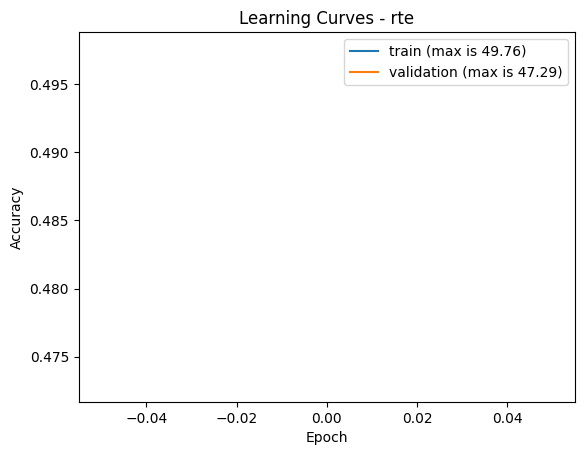

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.734
TRAIN ACC: 0.49799
VALIDATION ACC: 0.47292



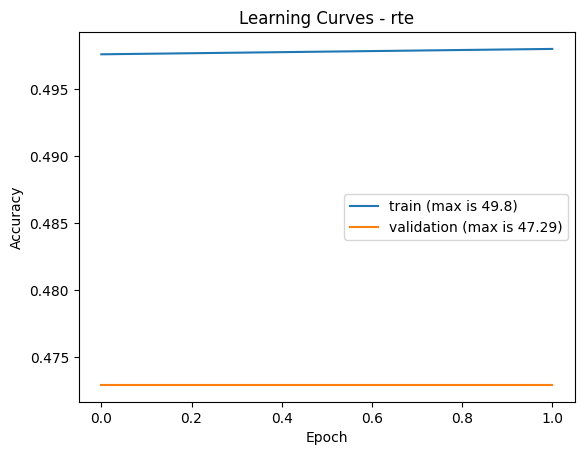

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.742
TRAIN ACC: 0.56466
VALIDATION ACC: 0.53791



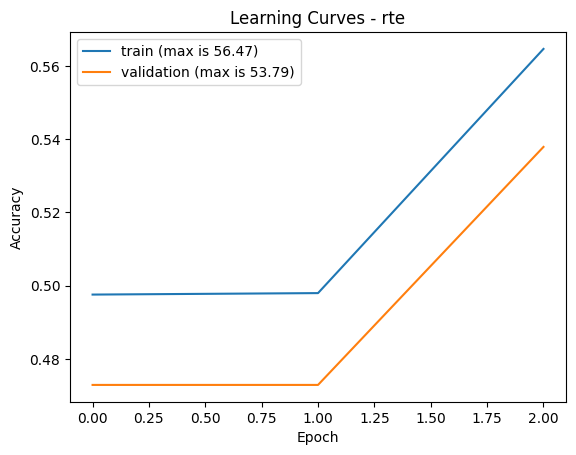

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.75
TRAIN ACC: 0.5502
VALIDATION ACC: 0.56679



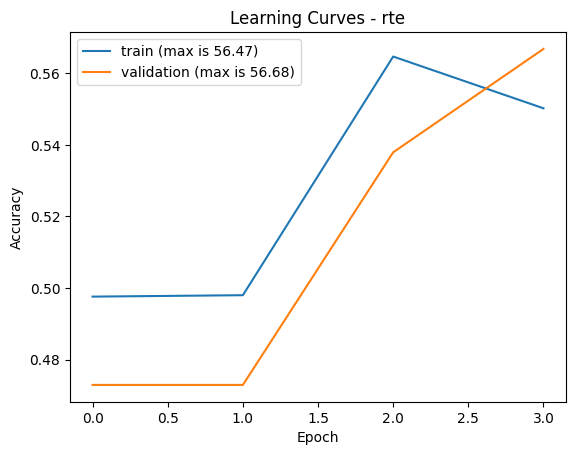

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Classifier-only
LR: 0.001
SEED: 42
Trainable parameters: 1538
Trainable tensors: 2
Gradient tensors: 0
Updated tensors: 2
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.5667870036101083
Final validation: 0.5667870036101083
Elapsed: 154.73s
Peak GPU memory: 0.453 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Classifier-only_lr0.001_seed42
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Classifier-only
LR: 0.001
SEED: 123


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
1538
Trainable tensors: 2
  classifier.weight (2, 768)
  classifier.bias (2,)
EPOCH: 0   TRAIN: 2490/2490   LOSS: 0.751
TRAIN ACC: 0.5494
VALIDATION ACC: 0.57401



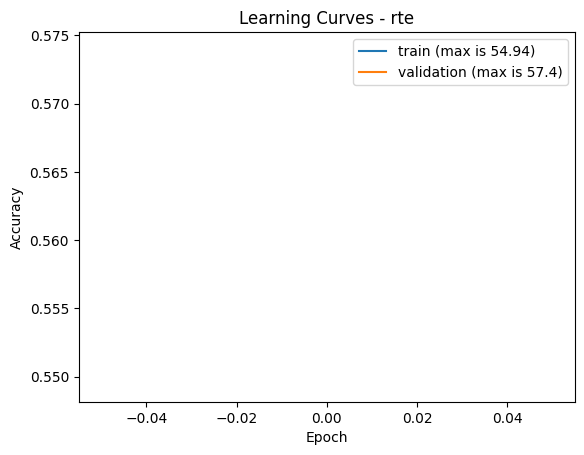

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.742
TRAIN ACC: 0.52892
VALIDATION ACC: 0.55596



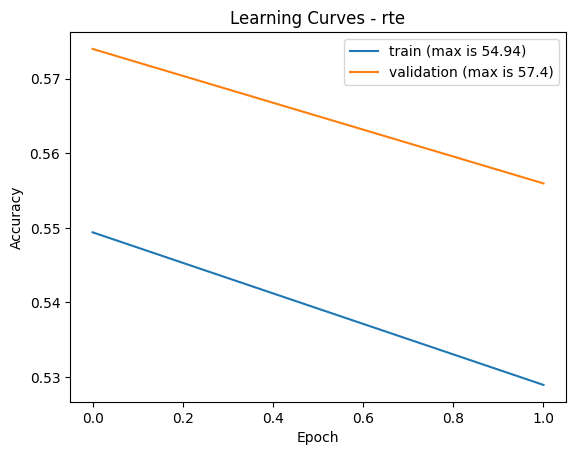

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.75
TRAIN ACC: 0.52731
VALIDATION ACC: 0.55596



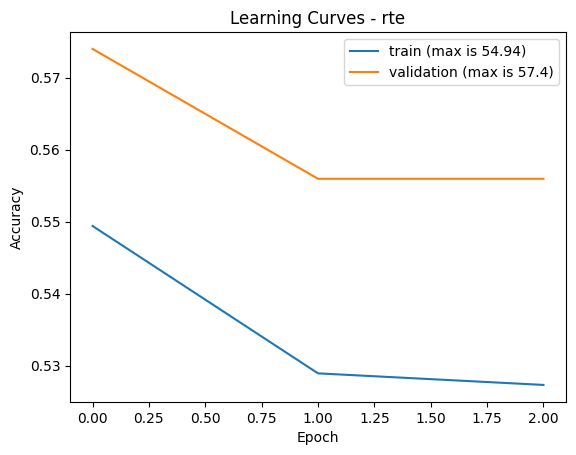

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.749
TRAIN ACC: 0.53133
VALIDATION ACC: 0.55596



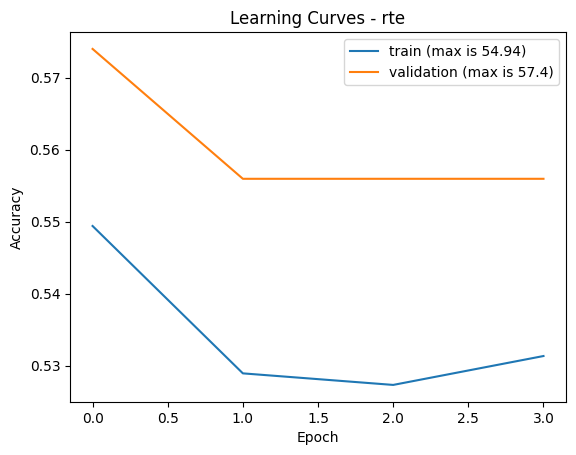

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Classifier-only
LR: 0.001
SEED: 123
Trainable parameters: 1538
Trainable tensors: 2
Gradient tensors: 0
Updated tensors: 2
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.5740072202166066
Final validation: 0.555956678700361
Elapsed: 154.56s
Peak GPU memory: 0.453 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Classifier-only_lr0.001_seed123
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Classifier-only
LR: 0.001
SEED: 2026


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
1538
Trainable tensors: 2
  classifier.weight (2, 768)
  classifier.bias (2,)
EPOCH: 0   TRAIN: 2490/2490   LOSS: 0.75
TRAIN ACC: 0.53414
VALIDATION ACC: 0.5343



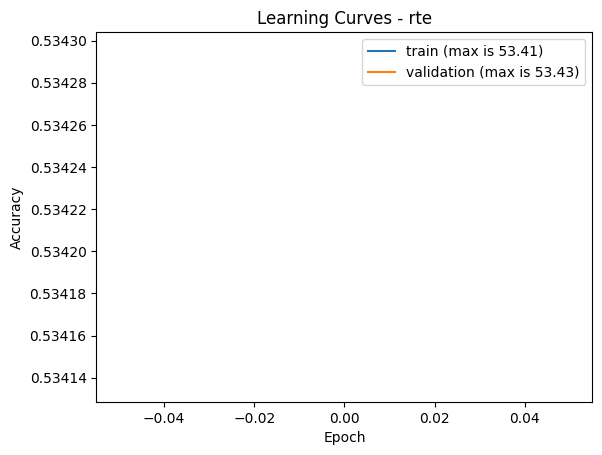

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.741
TRAIN ACC: 0.49799
VALIDATION ACC: 0.47292



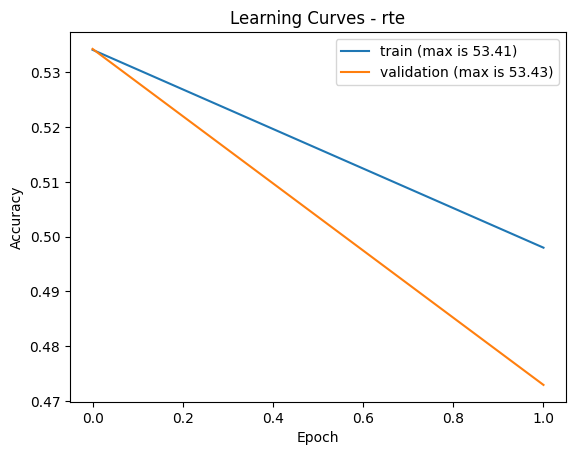

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.74
TRAIN ACC: 0.56345
VALIDATION ACC: 0.54513



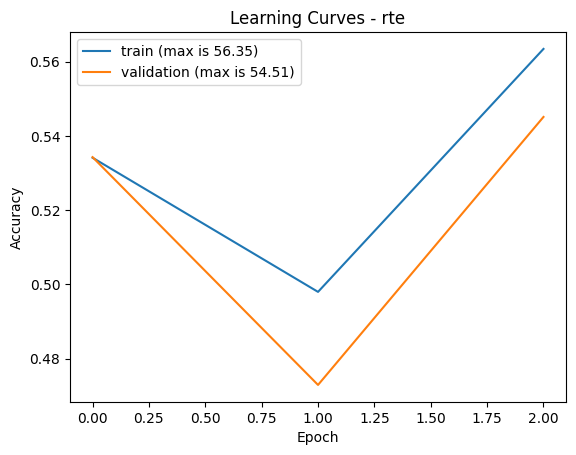

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.738
TRAIN ACC: 0.49799
VALIDATION ACC: 0.47292



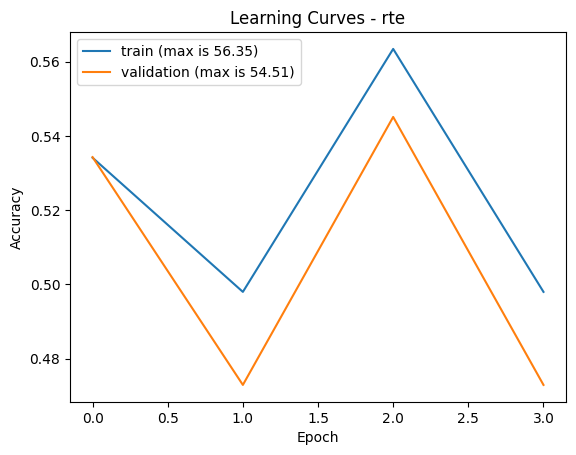

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Classifier-only
LR: 0.001
SEED: 2026
Trainable parameters: 1538
Trainable tensors: 2
Gradient tensors: 0
Updated tensors: 2
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.5451263537906137
Final validation: 0.4729241877256318
Elapsed: 154.71s
Peak GPU memory: 0.453 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Classifier-only_lr0.001_seed2026
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


实验组结束： Classifier-only


实验组： Full FT
LR： 2e-05
Seeds： [42, 123, 2026]


开始实验
METHOD: Full FT
LR: 2e-05
SEED: 42


HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/.huggingface.yaml
Retrying in 1s [Retry 1/5].
HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/.huggingface.yaml
Retrying in 2s [Retry 2/5].
HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/.huggingface.yaml
Retrying in 4s [Retry 3/5].
HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/.huggingface.yaml
Retrying in 8s [Retry 4/5].
HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-mll/glue/resolve/bcdcba79d07bc864c1c254ccfcedcce55bcc9a8c/.huggingface.yaml
Retrying in 8s [Retry 5/5].
HTTP Error 504 thrown while requesting HEAD https://huggingface.co/datasets/nyu-

Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
108311810
Trainable tensors: 201
  bert.embeddings.word_embeddings.weight (28996, 768)
  bert.embeddings.position_embeddings.weight (512, 768)
  bert.embeddings.token_type_embeddings.weight (2, 768)
  bert.embeddings.LayerNorm.weight (768,)
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.weight (768, 768)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.weight (768, 768)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.weight (768, 768)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.weight (768, 768)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.weight (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.weight (3072, 768)
  bert.encoder.layer.0.intermediate.d

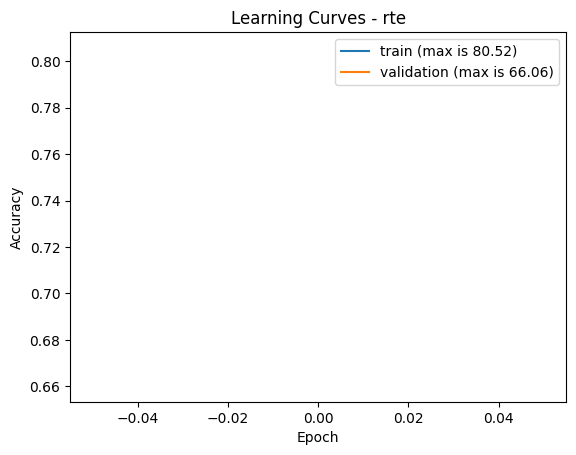

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.474
TRAIN ACC: 0.93293
VALIDATION ACC: 0.67148



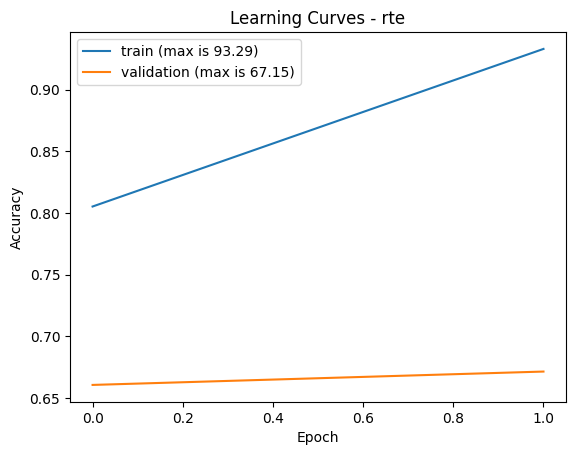

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.281
TRAIN ACC: 0.97349
VALIDATION ACC: 0.69314



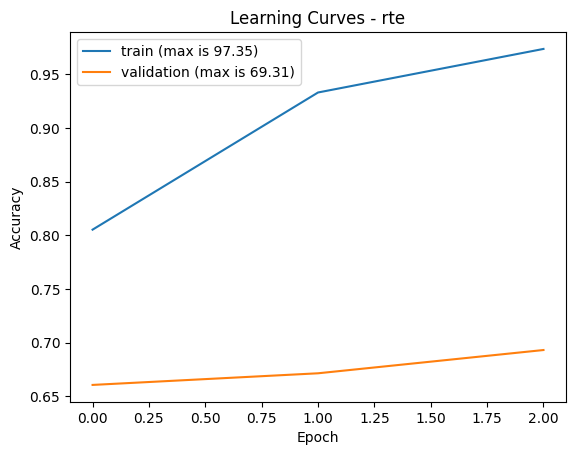

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.16
TRAIN ACC: 0.98876
VALIDATION ACC: 0.7148



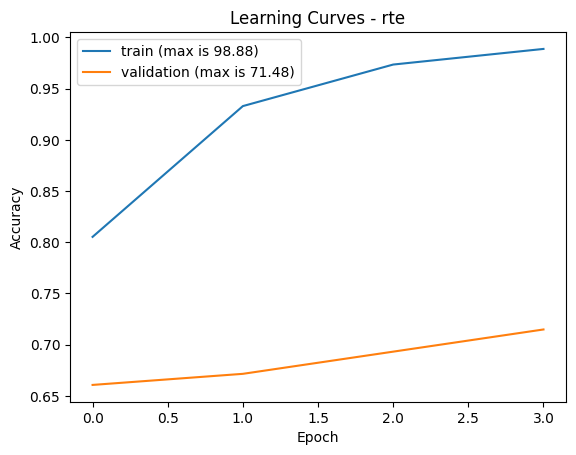

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Full FT
LR: 2e-05
SEED: 42
Trainable parameters: 108311810
Trainable tensors: 201
Gradient tensors: 0
Updated tensors: 201
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.7148014440433214
Final validation: 0.7148014440433214
Elapsed: 333.29s
Peak GPU memory: 2.061 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Full_FT_lr2e-05_seed42
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Full FT
LR: 2e-05
SEED: 123


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
108311810
Trainable tensors: 201
  bert.embeddings.word_embeddings.weight (28996, 768)
  bert.embeddings.position_embeddings.weight (512, 768)
  bert.embeddings.token_type_embeddings.weight (2, 768)
  bert.embeddings.LayerNorm.weight (768,)
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.weight (768, 768)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.weight (768, 768)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.weight (768, 768)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.weight (768, 768)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.weight (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.weight (3072, 768)
  bert.encoder.layer.0.intermediate.d

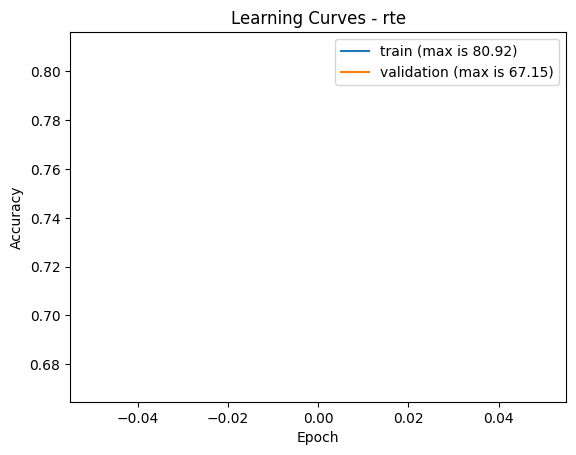

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.438
TRAIN ACC: 0.93896
VALIDATION ACC: 0.68231



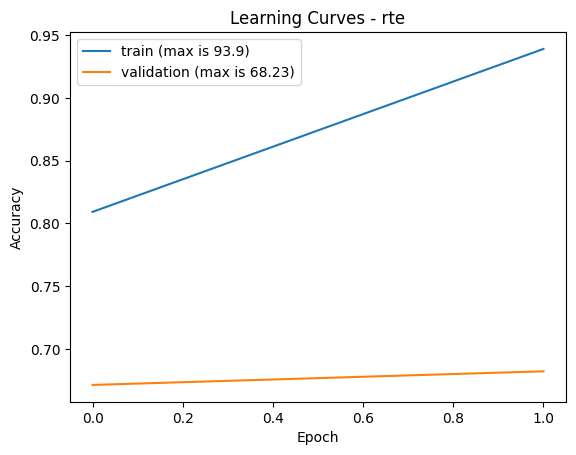

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.265
TRAIN ACC: 0.97309
VALIDATION ACC: 0.66787



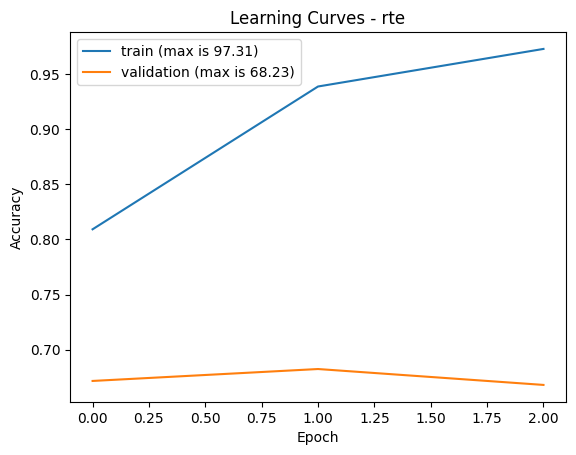

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.145
TRAIN ACC: 0.98876
VALIDATION ACC: 0.67509



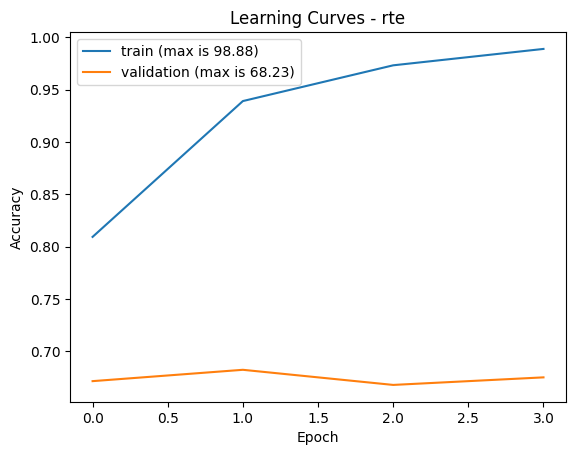

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Full FT
LR: 2e-05
SEED: 123
Trainable parameters: 108311810
Trainable tensors: 201
Gradient tensors: 0
Updated tensors: 201
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6823104693140795
Final validation: 0.6750902527075813
Elapsed: 335.91s
Peak GPU memory: 2.061 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Full_FT_lr2e-05_seed123
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Full FT
LR: 2e-05
SEED: 2026


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
108311810
Trainable tensors: 201
  bert.embeddings.word_embeddings.weight (28996, 768)
  bert.embeddings.position_embeddings.weight (512, 768)
  bert.embeddings.token_type_embeddings.weight (2, 768)
  bert.embeddings.LayerNorm.weight (768,)
  bert.embeddings.LayerNorm.bias (768,)
  bert.encoder.layer.0.attention.self.query.weight (768, 768)
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.attention.self.key.weight (768, 768)
  bert.encoder.layer.0.attention.self.key.bias (768,)
  bert.encoder.layer.0.attention.self.value.weight (768, 768)
  bert.encoder.layer.0.attention.self.value.bias (768,)
  bert.encoder.layer.0.attention.output.dense.weight (768, 768)
  bert.encoder.layer.0.attention.output.dense.bias (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.weight (768,)
  bert.encoder.layer.0.attention.output.LayerNorm.bias (768,)
  bert.encoder.layer.0.intermediate.dense.weight (3072, 768)
  bert.encoder.layer.0.intermediate.d

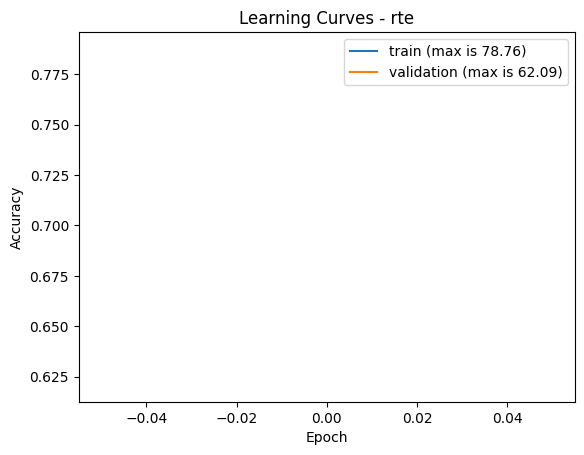

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.478
TRAIN ACC: 0.93213
VALIDATION ACC: 0.66787



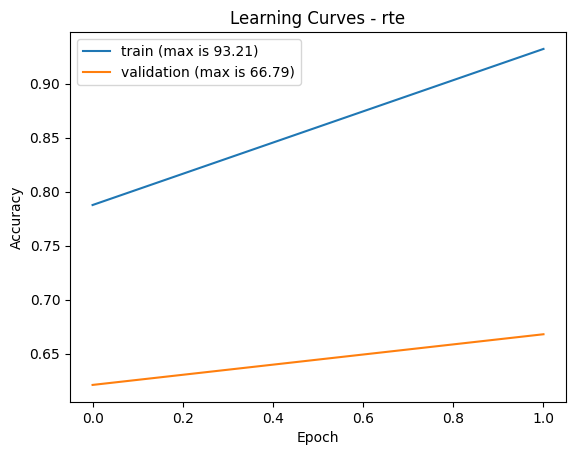

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.279
TRAIN ACC: 0.9743
VALIDATION ACC: 0.67509



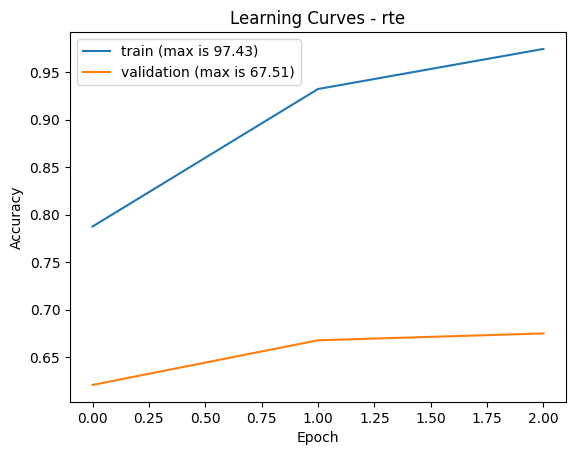

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.17
TRAIN ACC: 0.98434
VALIDATION ACC: 0.66787



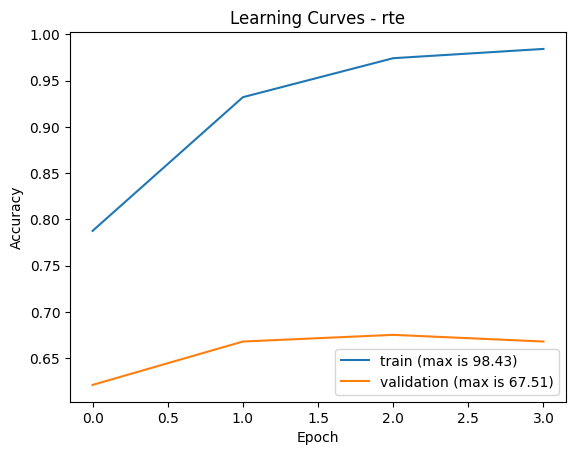

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Full FT
LR: 2e-05
SEED: 2026
Trainable parameters: 108311810
Trainable tensors: 201
Gradient tensors: 0
Updated tensors: 201
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6750902527075813
Final validation: 0.6678700361010831
Elapsed: 337.29s
Peak GPU memory: 2.061 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Full_FT_lr2e-05_seed2026
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


实验组结束： Full FT


实验组： Partial BitFit
LR： 0.005
Seeds： [42, 123, 2026]


开始实验
METHOD: Partial BitFit
LR: 0.005
SEED: 42


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
48386
Trainable tensors: 27
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.2.attention.self.query.bias (768,)
  bert.encoder.layer.2.intermediate.dense.bias (3072,)
  bert.encoder.layer.3.attention.self.query.bias (768,)
  bert.encoder.layer.3.intermediate.dense.bias (3072,)
  bert.encoder.layer.4.attention.self.query.bias (768,)
  bert.encoder.layer.4.intermediate.dense.bias (3072,)
  bert.encoder.layer.5.attention.self.query.bias (768,)
  bert.encoder.layer.5.intermediate.dense.bias (3072,)
  bert.encoder.layer.6.attention.self.query.bias (768,)
  bert.encoder.layer.6.intermediate.dense.bias (3072,)
  bert.encoder.layer.7.attention.self.query.bias (768,)
  bert.encoder.layer.7.intermediate.dense.bias (3072,)
  bert.encoder.layer.8.attention.self.query.bias (768,)
  ber

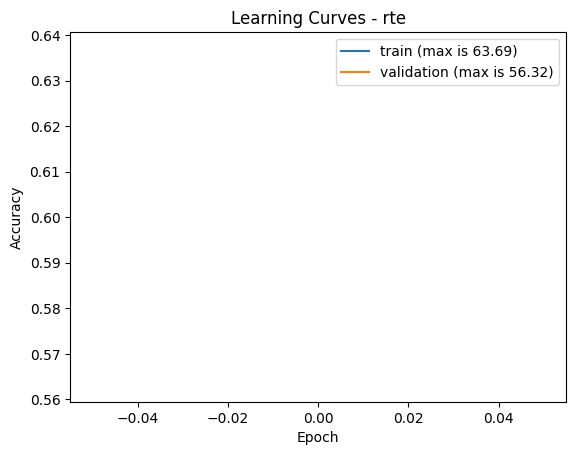

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.773
TRAIN ACC: 0.68032
VALIDATION ACC: 0.61011



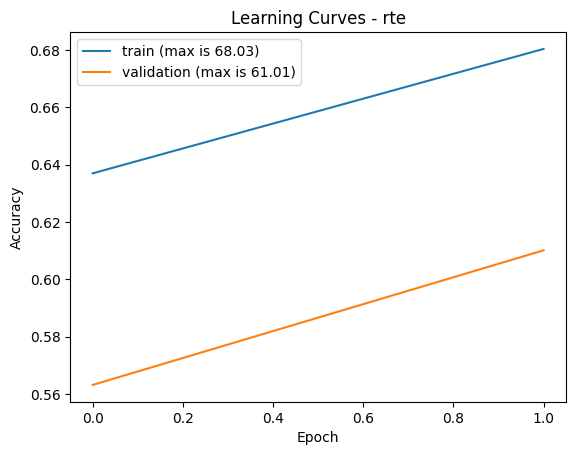

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.658
TRAIN ACC: 0.78514
VALIDATION ACC: 0.67509



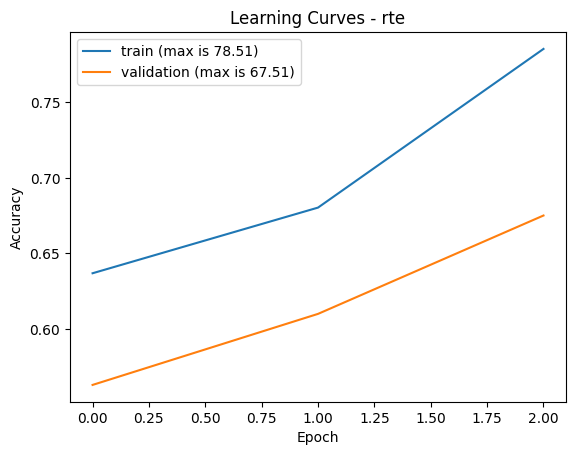

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.571
TRAIN ACC: 0.86064
VALIDATION ACC: 0.68953



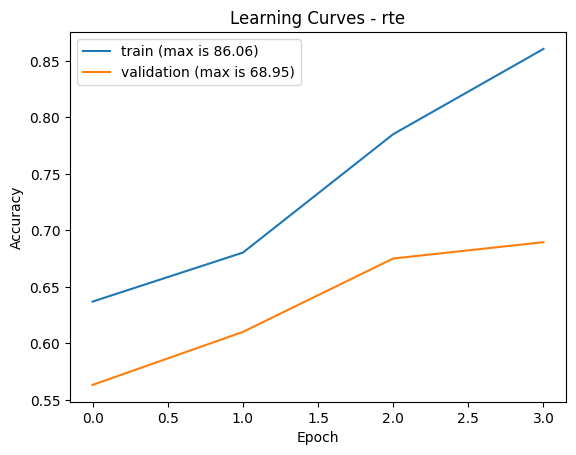

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Partial BitFit
LR: 0.005
SEED: 42
Trainable parameters: 48386
Trainable tensors: 27
Gradient tensors: 0
Updated tensors: 27
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6895306859205776
Final validation: 0.6895306859205776
Elapsed: 230.01s
Peak GPU memory: 0.824 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Partial_BitFit_lr0.005_seed42
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Partial BitFit
LR: 0.005
SEED: 123


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
48386
Trainable tensors: 27
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.2.attention.self.query.bias (768,)
  bert.encoder.layer.2.intermediate.dense.bias (3072,)
  bert.encoder.layer.3.attention.self.query.bias (768,)
  bert.encoder.layer.3.intermediate.dense.bias (3072,)
  bert.encoder.layer.4.attention.self.query.bias (768,)
  bert.encoder.layer.4.intermediate.dense.bias (3072,)
  bert.encoder.layer.5.attention.self.query.bias (768,)
  bert.encoder.layer.5.intermediate.dense.bias (3072,)
  bert.encoder.layer.6.attention.self.query.bias (768,)
  bert.encoder.layer.6.intermediate.dense.bias (3072,)
  bert.encoder.layer.7.attention.self.query.bias (768,)
  bert.encoder.layer.7.intermediate.dense.bias (3072,)
  bert.encoder.layer.8.attention.self.query.bias (768,)
  ber

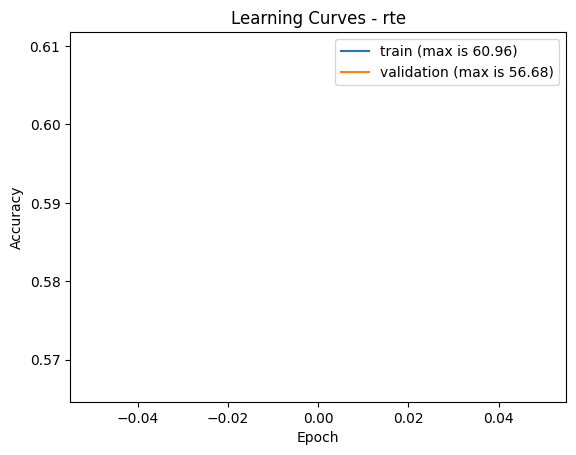

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.826
TRAIN ACC: 0.68353
VALIDATION ACC: 0.59206



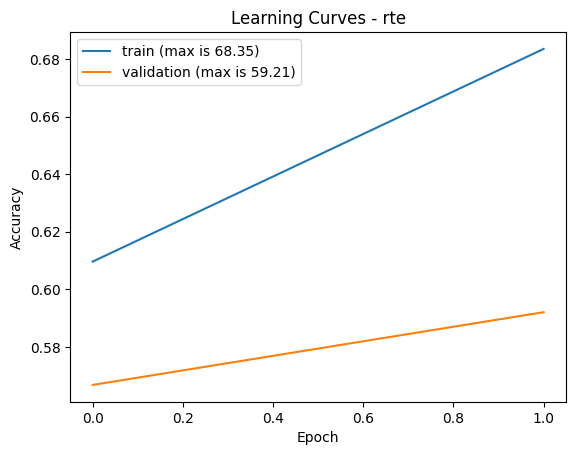

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.697
TRAIN ACC: 0.63133
VALIDATION ACC: 0.58845



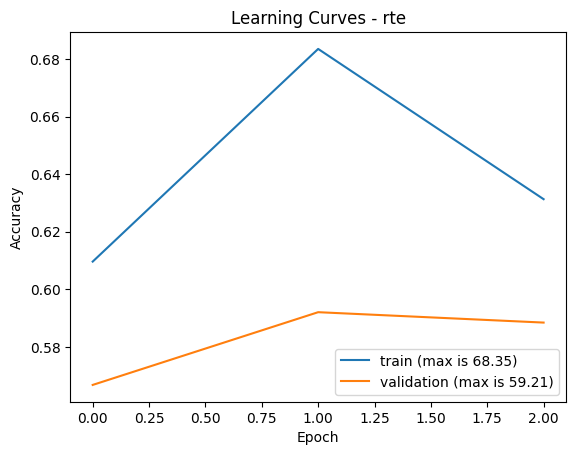

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.612
TRAIN ACC: 0.86948
VALIDATION ACC: 0.66787



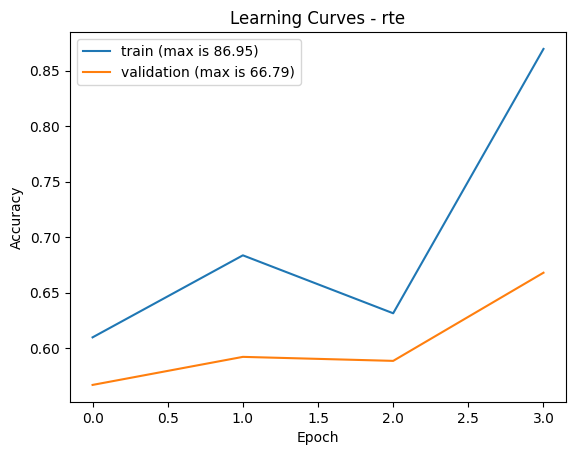

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Partial BitFit
LR: 0.005
SEED: 123
Trainable parameters: 48386
Trainable tensors: 27
Gradient tensors: 0
Updated tensors: 27
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6678700361010831
Final validation: 0.6678700361010831
Elapsed: 230.32s
Peak GPU memory: 0.824 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Partial_BitFit_lr0.005_seed123
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


开始实验
METHOD: Partial BitFit
LR: 0.005
SEED: 2026


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.



Trainable parameters:
48386
Trainable tensors: 27
  bert.encoder.layer.0.attention.self.query.bias (768,)
  bert.encoder.layer.0.intermediate.dense.bias (3072,)
  bert.encoder.layer.1.attention.self.query.bias (768,)
  bert.encoder.layer.1.intermediate.dense.bias (3072,)
  bert.encoder.layer.2.attention.self.query.bias (768,)
  bert.encoder.layer.2.intermediate.dense.bias (3072,)
  bert.encoder.layer.3.attention.self.query.bias (768,)
  bert.encoder.layer.3.intermediate.dense.bias (3072,)
  bert.encoder.layer.4.attention.self.query.bias (768,)
  bert.encoder.layer.4.intermediate.dense.bias (3072,)
  bert.encoder.layer.5.attention.self.query.bias (768,)
  bert.encoder.layer.5.intermediate.dense.bias (3072,)
  bert.encoder.layer.6.attention.self.query.bias (768,)
  bert.encoder.layer.6.intermediate.dense.bias (3072,)
  bert.encoder.layer.7.attention.self.query.bias (768,)
  bert.encoder.layer.7.intermediate.dense.bias (3072,)
  bert.encoder.layer.8.attention.self.query.bias (768,)
  ber

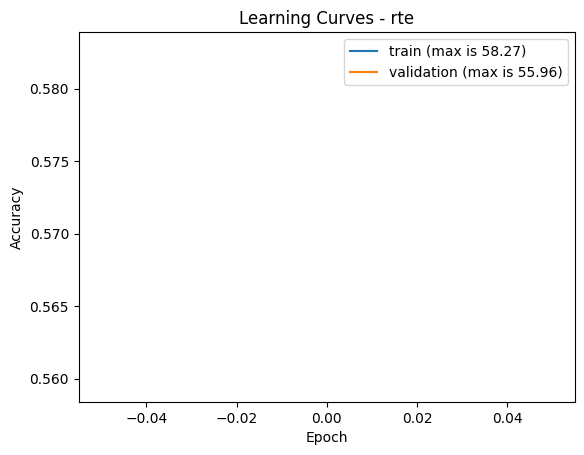

EPOCH: 1   TRAIN: 2490/2490   LOSS: 0.752
TRAIN ACC: 0.71807
VALIDATION ACC: 0.62455



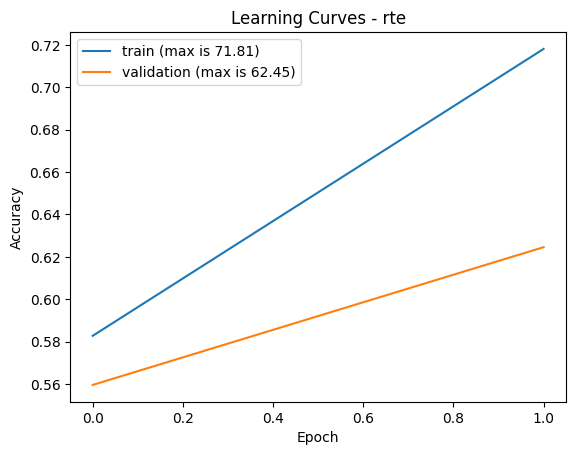

EPOCH: 2   TRAIN: 2490/2490   LOSS: 0.648
TRAIN ACC: 0.6241
VALIDATION ACC: 0.59928



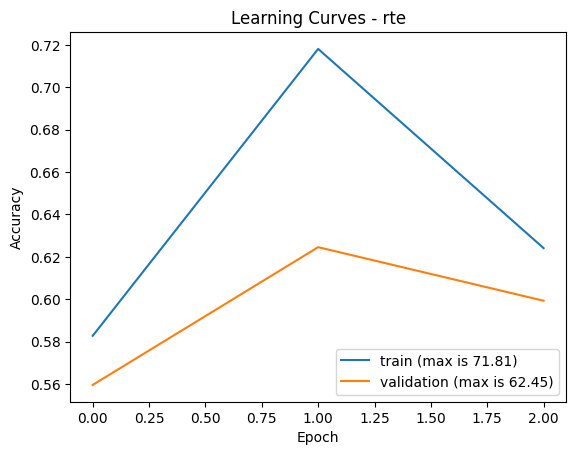

EPOCH: 3   TRAIN: 2490/2490   LOSS: 0.592
TRAIN ACC: 0.86104
VALIDATION ACC: 0.64621



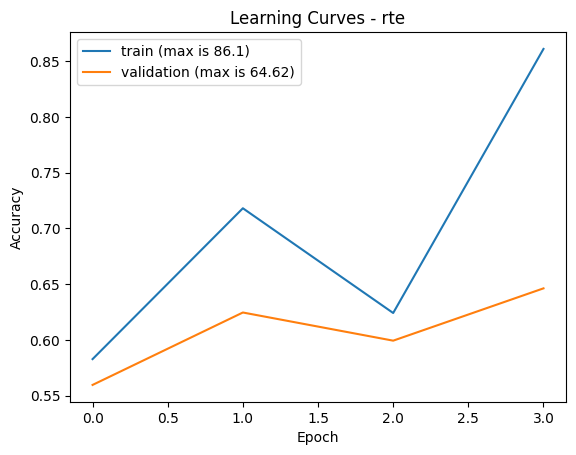

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]



实验完成
METHOD: Partial BitFit
LR: 0.005
SEED: 2026
Trainable parameters: 48386
Trainable tensors: 27
Gradient tensors: 0
Updated tensors: 27
Not updated tensors: 0
Optimizer steps: [1248.0]
Best validation: 0.6462093862815884
Final validation: 0.6462093862815884
Elapsed: 230.56s
Peak GPU memory: 0.824 GB
Model saved: /content/drive/MyDrive/nlp实践/BitFit_models/Partial_BitFit_lr0.005_seed2026
JSON 已立即保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


实验组结束： Partial BitFit


12 个实验全部执行完毕
当前完成数量： 12
结果文件： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_stage_b.json


In [7]:
# ============================================================
# Cell 6
# 正式运行 12 个实验
# ============================================================

SEEDS = [
    42,
    123,
    2026
]

# ============================================================
# 1. BitFit
# ============================================================

run_grid(
    method="BitFit",

    components=[
        "bias"
    ],

    encoder_trainable=False,

    lr=5e-4,

    seeds=SEEDS
)


# ============================================================
# 2. Classifier-only
# ============================================================

run_grid(
    method="Classifier-only",

    components=[],

    encoder_trainable=False,

    lr=1e-3,

    seeds=SEEDS
)


# ============================================================
# 3. Full Fine-tuning
# ============================================================

run_grid(
    method="Full FT",

    components=None,

    encoder_trainable=True,

    lr=2e-5,

    seeds=SEEDS
)


# ============================================================
# 4. Partial BitFit
# ============================================================

run_grid(
    method="Partial BitFit",

    components=[
        "attention.self.query.bias",
        "intermediate.dense.bias"
    ],

    encoder_trainable=False,

    lr=5e-3,

    seeds=SEEDS
)


print("\n")
print("=" * 70)
print("12 个实验全部执行完毕")
print("=" * 70)

print(
    "当前完成数量：",
    len(all_results)
)

print(
    "结果文件：",
    RESULTS_PATH
)

In [8]:
# ============================================================
# Cell 7
# 最终结果汇总
# ============================================================

import pandas as pd
import numpy as np
import os
import json

# ------------------------------------------------------------
# 重新读取最新 JSON
# ------------------------------------------------------------

with open(
    RESULTS_PATH,
    "r",
    encoding="utf-8"
) as f:

    final_results = json.load(f)

# ------------------------------------------------------------
# 检查数量
# ------------------------------------------------------------

print(
    "完成实验数量：",
    len(final_results)
)

expected = 12

if len(final_results) < expected:

    print(
        f"\n注意：目前只有 {len(final_results)}/{expected} 个实验完成。"
    )

else:

    print(
        "\n12/12 个实验全部完成。"
    )

# ------------------------------------------------------------
# DataFrame
# ------------------------------------------------------------

rows = []

for r in final_results:

    rows.append({

        "method":
            r["method"],

        "lr":
            r["lr"],

        "seed":
            r["seed"],

        "trainable_params":
            r["trainable_params"],

        "trainable_tensors":
            r["trainable_tensors"],

        "final_val_acc":
            r["final_val_acc"],

        "best_val_acc":
            r["best_val_acc"],

        "elapsed_s":
            r["elapsed"],

        "peak_gpu_gb":
            r["peak_mem"],

        "optimizer_step":
            (
                r["optimizer_steps"][-1]
                if r["optimizer_steps"]
                else None
            ),

        "gradient_tensors":
            r["gradient_tensors"],

        "updated_tensors":
            r["updated_tensors"],

        "not_updated_tensors":
            r["not_updated_tensors"],

        "max_parameter_change":
            r["max_parameter_change"]
    })


df = pd.DataFrame(rows)

df = df.sort_values(
    [
        "method",
        "seed"
    ]
)

print("\n")
print("=" * 100)
print("逐实验结果")
print("=" * 100)

print(
    df.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

summary = (
    df
    .groupby(
        [
            "method",
            "lr"
        ]
    )
    .agg(

        n=(
            "seed",
            "count"
        ),

        final_val_mean=(
            "final_val_acc",
            "mean"
        ),

        final_val_std=(
            "final_val_acc",
            "std"
        ),

        best_val_mean=(
            "best_val_acc",
            "mean"
        ),

        best_val_std=(
            "best_val_acc",
            "std"
        ),

        trainable_params=(
            "trainable_params",
            "first"
        ),

        trainable_tensors=(
            "trainable_tensors",
            "first"
        ),

        time_mean_s=(
            "elapsed_s",
            "mean"
        ),

        memory_mean_gb=(
            "peak_gpu_gb",
            "mean"
        ),

        updated_tensors=(
            "updated_tensors",
            "first"
        )
    )
    .reset_index()
)

summary = summary.sort_values(
    "final_val_mean",
    ascending=False
)

print("\n")
print("=" * 100)
print("最终方法汇总")
print("=" * 100)

print(
    summary.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 保存 CSV
# ------------------------------------------------------------

ALL_CSV = os.path.join(
    RESULT_ROOT,
    "bitfit_all_results.csv"
)

SUMMARY_CSV = os.path.join(
    RESULT_ROOT,
    "bitfit_summary.csv"
)

df.to_csv(
    ALL_CSV,
    index=False,
    encoding="utf-8-sig"
)

summary.to_csv(
    SUMMARY_CSV,
    index=False,
    encoding="utf-8-sig"
)

print("\n")
print("已保存：")
print(RESULTS_PATH)
print(ALL_CSV)
print(SUMMARY_CSV)

完成实验数量： 12

12/12 个实验全部完成。


逐实验结果
         method      lr  seed  trainable_params  trainable_tensors  final_val_acc  best_val_acc  elapsed_s  peak_gpu_gb  optimizer_step  gradient_tensors  updated_tensors  not_updated_tensors  max_parameter_change
         BitFit 0.00050    42            104450                100       0.703971      0.703971 220.898242     0.828384          1248.0                 0              100                    0              0.147575
         BitFit 0.00050   123            104450                100       0.646209      0.646209 230.893409     0.827774          1248.0                 0              100                    0              0.133759
         BitFit 0.00050  2026            104450                100       0.638989      0.671480 231.466470     0.827774          1248.0                 0              100                    0              0.144497
Classifier-only 0.00100    42              1538                  2       0.566787      0.566787 154.734921   

In [9]:
# ============================================================
# Cell 8
# BitFit 实际更新检查
# ============================================================

print("=" * 80)
print("实际参数更新检查")
print("=" * 80)

for r in final_results:

    print("\n")
    print(
        f"{r['method']} | "
        f"LR={r['lr']} | "
        f"seed={r['seed']}"
    )

    print(
        "Trainable:",
        r["trainable_params"]
    )

    print(
        "Gradient tensors:",
        r["gradient_tensors"],
        "/",
        r["trainable_tensors"]
    )

    print(
        "Updated tensors:",
        r["updated_tensors"],
        "/",
        r["trainable_tensors"]
    )

    print(
        "Not updated:",
        r["not_updated_tensors"]
    )

    print(
        "Max parameter change:",
        r["max_parameter_change"]
    )

    if (
        r["gradient_tensors"]
        == r["trainable_tensors"]
        and
        r["updated_tensors"]
        == r["trainable_tensors"]
    ):

        print(
            "CHECK: PASS"
        )

    else:

        print(
            "CHECK: NEED REVIEW"
        )

print("\n检查结束。")

实际参数更新检查


BitFit | LR=0.0005 | seed=42
Trainable: 104450
Gradient tensors: 0 / 100
Updated tensors: 100 / 100
Not updated: 0
Max parameter change: 0.14757515490055084
CHECK: NEED REVIEW


BitFit | LR=0.0005 | seed=123
Trainable: 104450
Gradient tensors: 0 / 100
Updated tensors: 100 / 100
Not updated: 0
Max parameter change: 0.13375931978225708
CHECK: NEED REVIEW


BitFit | LR=0.0005 | seed=2026
Trainable: 104450
Gradient tensors: 0 / 100
Updated tensors: 100 / 100
Not updated: 0
Max parameter change: 0.14449742436408997
CHECK: NEED REVIEW


Classifier-only | LR=0.001 | seed=42
Trainable: 1538
Gradient tensors: 0 / 2
Updated tensors: 2 / 2
Not updated: 0
Max parameter change: 0.07239237427711487
CHECK: NEED REVIEW


Classifier-only | LR=0.001 | seed=123
Trainable: 1538
Gradient tensors: 0 / 2
Updated tensors: 2 / 2
Not updated: 0
Max parameter change: 0.09482225775718689
CHECK: NEED REVIEW


Classifier-only | LR=0.001 | seed=2026
Trainable: 1538
Gradient tensors: 0 / 2
Updated tensors:

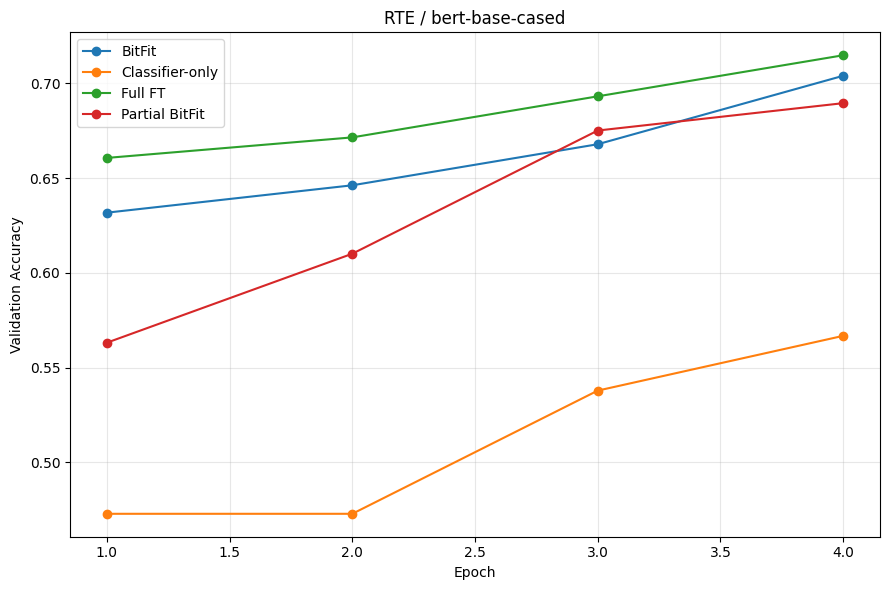

学习曲线已保存： /content/drive/MyDrive/nlp实践/BitFit_results/bitfit_learning_curves.png


In [10]:
# ============================================================
# Cell 9
# 学习曲线
# ============================================================

import matplotlib.pyplot as plt

plt.figure(
    figsize=(9, 6)
)

for method in [
    "BitFit",
    "Classifier-only",
    "Full FT",
    "Partial BitFit"
]:

    candidates = [
        r
        for r in final_results
        if r["method"] == method
        and r["seed"] == 42
    ]

    if not candidates:
        continue

    r = candidates[0]

    epochs = list(
        range(
            1,
            len(r["val_accs"]) + 1
        )
    )

    plt.plot(
        epochs,
        r["val_accs"],
        marker="o",
        label=method
    )

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Validation Accuracy"
)

plt.title(
    "RTE / bert-base-cased"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

CURVE_PATH = os.path.join(
    RESULT_ROOT,
    "bitfit_learning_curves.png"
)

plt.savefig(
    CURVE_PATH,
    dpi=150
)

plt.show()

print(
    "学习曲线已保存：",
    CURVE_PATH
)

In [12]:
# ============================================================
# BitFit 实际 Gradient 检查
# 修正版：使用 GLUEvaluator.data_loaders["train"]
# 只做一次 forward + backward，不进行正式训练
# ============================================================

import sys
import random
import numpy as np
import torch

BITFIT_PATH = "/content/BitFit"

if BITFIT_PATH not in sys.path:
    sys.path.insert(0, BITFIT_PATH)

import glue_evaluator

GLUEvaluator = glue_evaluator.GLUEvaluator


def gradient_check(
    method,
    trainable_components,
    encoder_trainable,
    lr,
    seed=42
):

    print("\n" + "=" * 75)
    print(f"Gradient Check: {method}")
    print(f"LR: {lr}")
    print(f"SEED: {seed}")
    print("=" * 75)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    random.seed(seed)
    np.random.seed(seed)

    ev = GLUEvaluator(
        "rte",
        "bert-base-cased",
        "cuda"
    )

    ev.preprocess_dataset(
        padding="max_length",
        max_sequence_len=128,
        batch_size=8
    )

    ev.training_preparation(
        learning_rate=lr,
        optimizer="adamw",
        encoder_trainable=encoder_trainable,
        trainable_components=trainable_components,
        verbose=False
    )

    ev.model = ev.model.to(ev.device)

    ev.model.train()

    trainable_params = [
        (name, p)
        for name, p in ev.model.named_parameters()
        if p.requires_grad
    ]

    total_trainable = sum(
        p.numel()
        for _, p in trainable_params
    )

    print(
        f"Trainable tensors: {len(trainable_params)}"
    )

    print(
        f"Trainable parameters: {total_trainable:,}"
    )

    # --------------------------------------------------------
    # 使用 GLUEvaluator 实际的数据加载器
    # --------------------------------------------------------

    train_loader = ev.data_loaders["train"]

    batch = next(iter(train_loader))

    batch = tuple(
        x.to(ev.device)
        for x in batch
    )

    if "roberta" in ev.model_name:

        input_ids, attention_mask, labels = batch

        token_type_ids = None

    else:

        input_ids, attention_mask, token_type_ids, labels = batch

    # --------------------------------------------------------
    # forward
    # --------------------------------------------------------

    ev.optimizer.zero_grad(set_to_none=True)

    outputs = ev.model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        token_type_ids=token_type_ids
    )

    logits = outputs.logits

    labels = labels.view(-1)

    logits = logits.view(
        -1,
        ev.num_labels
    )

    criterion = torch.nn.CrossEntropyLoss()

    loss = criterion(
        logits,
        labels
    )

    print(
        f"Loss before backward: {loss.item():.6f}"
    )

    # --------------------------------------------------------
    # backward
    # --------------------------------------------------------

    loss.backward()

    # --------------------------------------------------------
    # 检查每一个 trainable tensor 是否存在 gradient
    # --------------------------------------------------------

    gradient_params = []
    no_gradient_params = []

    for name, param in trainable_params:

        if param.grad is not None:

            grad_norm = (
                param.grad.detach()
                .norm()
                .item()
            )

            gradient_params.append(
                (
                    name,
                    param.numel(),
                    grad_norm
                )
            )

        else:

            no_gradient_params.append(
                (
                    name,
                    param.numel()
                )
            )

    # --------------------------------------------------------
    # 输出结果
    # --------------------------------------------------------

    print()
    print("=" * 75)
    print("Gradient 检查结果")
    print("=" * 75)

    print(
        f"Gradient tensors: "
        f"{len(gradient_params)} / "
        f"{len(trainable_params)}"
    )

    print()

    if gradient_params:

        print("前 20 个 gradient 参数:")

        for name, numel, grad_norm in gradient_params[:20]:

            print(
                f"{name:<65} "
                f"numel={numel:<6} "
                f"grad_norm={grad_norm:.6e}"
            )

    if len(gradient_params) > 20:

        print(
            f"... 其余 "
            f"{len(gradient_params) - 20} 个省略"
        )

    if no_gradient_params:

        print()
        print("没有 gradient 的参数:")

        for name, numel in no_gradient_params:

            print(
                f"{name:<65} "
                f"numel={numel}"
            )

    print()
    print("=" * 75)

    if len(gradient_params) == len(trainable_params):

        print("CHECK: PASS")

        print(
            "所有可训练参数都在 backward 后获得了 gradient。"
        )

    else:

        print("CHECK: NEED REVIEW")

        print(
            f"有 {len(no_gradient_params)} "
            f"个可训练参数没有 gradient。"
        )

    print("=" * 75)

    ev.optimizer.zero_grad(set_to_none=True)

    del ev
    del batch
    del outputs
    del logits
    del loss

    torch.cuda.empty_cache()


# ============================================================
# 1. BitFit
# ============================================================

gradient_check(
    method="BitFit",
    trainable_components=["bias"],
    encoder_trainable=False,
    lr=5e-4,
    seed=42
)


# ============================================================
# 2. Classifier-only
# ============================================================

gradient_check(
    method="Classifier-only",
    trainable_components=[],
    encoder_trainable=False,
    lr=1e-3,
    seed=42
)


# ============================================================
# 3. Full FT
# ============================================================

gradient_check(
    method="Full FT",
    trainable_components=None,
    encoder_trainable=True,
    lr=2e-5,
    seed=42
)


# ============================================================
# 4. Partial BitFit
# ============================================================

gradient_check(
    method="Partial BitFit",
    trainable_components=[
        "attention.self.query.bias",
        "intermediate.dense.bias"
    ],
    encoder_trainable=False,
    lr=5e-3,
    seed=42
)


print("\n" + "=" * 75)
print("Gradient 检查全部完成")
print("=" * 75)


Gradient Check: BitFit
LR: 0.0005
SEED: 42


Map: 100%|##########| 2490/2490 [00:00<?, ? examples/s]

Map: 100%|##########| 277/277 [00:00<?, ? examples/s]

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (15 outputs left out)

Map: 100%|##########| 3000/3000 [00:00<?, ? examples/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Trainable tensors: 27
Trainable parameters: 48,386
Loss before backward: 0.651372

Gradient 检查结果
Gradient tensors: 27 / 27

前 20 个 gradient 参数:
bert.encoder.layer.0.attention.self.query.bias                    numel=768    grad_norm=2.687952e-03
bert.encoder.layer.0.intermediate.dense.bias                      numel=3072   grad_norm=8.205488e-03
bert.encoder.layer.1.attention.self.query.bias                    numel=768    grad_norm=4.369021e-03
bert.encoder.layer.1.intermediate.dense.bias                      numel=3072   grad_norm=8.151464e-03
bert.encoder.layer.2.attention.self.query.bias                    numel=768    grad_norm=4.059438e-03
bert.encoder.layer.2.intermediate.dense.bias                      numel=3072   grad_norm=8.476714e-03
bert.encoder.layer.3.attention.self.query.bias                    numel=768    grad_norm=3.447890e-03
bert.encoder.layer.3.intermediate.dense.bias                      numel=3072   grad_norm=9.847440e-03
bert.encoder.layer.4.attention.self.quer